In [1]:
!pip install -q tensorflow-datasets ultralytics opencv-python seaborn importlib-resources

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
import random

from collections import Counter
from PIL import Image

In [3]:
dataset, info = tfds.load(
    "voc/2007",
    split="train",
    with_info=True,
    shuffle_files=True
)

print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2007/incomplete.AWAR01_5.0.0/voc-test.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2007/incomplete.AWAR01_5.0.0/voc-train.tfrecord-[0-9][0-9][0-9][0-9][0…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2007/incomplete.AWAR01_5.0.0/voc-validation.tfrecord-[0-9][0-9][0-9][0…

Dataset voc downloaded and prepared to /root/tensorflow_datasets/voc/2007/5.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='voc',
    full_name='voc/2007/5.0.0',
    description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge,
    corresponding to the Classification and Detection competitions.
    
    In the Classification competition, the goal is to predict the set of labels
    contained in the image, while in the Detection competition the goal is to
    predict the bounding box and label of each individual object.
    annotations.
    """,
    config_description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge
    2007, a.k.a. VOC2007.
    
    A total of 9963 images are included in this dataset, where each image
    contains a set of objects, out of 20 different classes, making a total of
    24640 annotated objects.
    
    """,
    homepage='http://host.robots.ox.ac.uk/pasc

In [4]:
train_ds = tfds.load("voc/2007", split="train")
val_ds = tfds.load("voc/2007", split="validation")
test_ds = tfds.load("voc/2007", split="test")

In [5]:
print("Dataset features:")
print(info.features)

print("\nDataset splits:")
print(info.splits)

print("\nNumber of training images:")
print(info.splits["train"].num_examples)

print("\nNumber of validation images:")
print(info.splits["validation"].num_examples)

print("\nNumber of test images:")
print(info.splits["test"].num_examples)

Dataset features:
FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'image/filename': Text(shape=(), dtype=string),
    'labels': Sequence(ClassLabel(shape=(), dtype=int64, num_classes=20)),
    'labels_no_difficult': Sequence(ClassLabel(shape=(), dtype=int64, num_classes=20)),
    'objects': Sequence({
        'bbox': BBoxFeature(shape=(4,), dtype=float32),
        'is_difficult': bool,
        'is_truncated': bool,
        'label': ClassLabel(shape=(), dtype=int64, num_classes=20),
        'pose': ClassLabel(shape=(), dtype=int64, num_classes=5),
    }),
})

Dataset splits:
{Split('test'): <SplitInfo num_examples=4952, num_shards=4>, Split('train'): <SplitInfo num_examples=2501, num_shards=2>, Split('validation'): <SplitInfo num_examples=2510, num_shards=2>}

Number of training images:
2501

Number of validation images:
2510

Number of test images:
4952


In [6]:
class_names = info.features["objects"]["label"].names

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, name)

Number of classes: 20
0 aeroplane
1 bicycle
2 bird
3 boat
4 bottle
5 bus
6 car
7 cat
8 chair
9 cow
10 diningtable
11 dog
12 horse
13 motorbike
14 person
15 pottedplant
16 sheep
17 sofa
18 train
19 tvmonitor


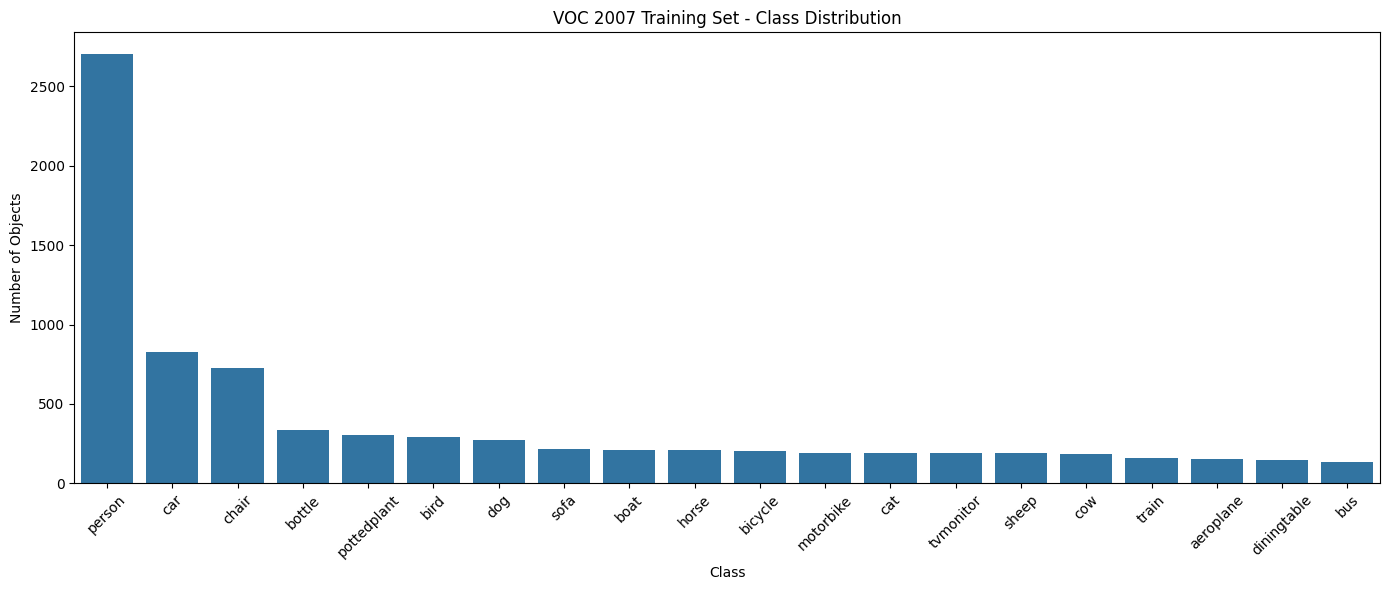

In [7]:
class_counts = Counter()

for example in train_ds:
    labels = example["objects"]["label"].numpy()

    for label in labels:
        class_counts[class_names[int(label)]] += 1

class_df = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Number of Objects"]
).sort_values(
    "Number of Objects",
    ascending=False
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=class_df,
    x="Class",
    y="Number of Objects"
)

plt.xticks(rotation=45)
plt.title("VOC 2007 Training Set - Class Distribution")
plt.tight_layout()
plt.show()

Average width: 471.97600959616153
Average height: 383.8740503798481
Minimum width: 127
Maximum width: 500


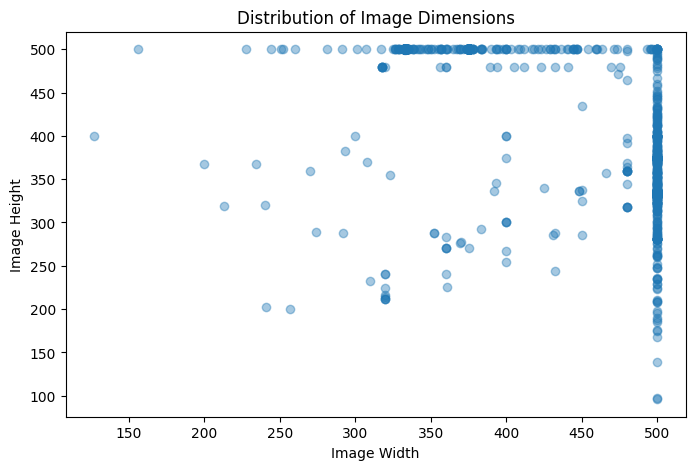

In [8]:
widths = []
heights = []

for example in train_ds:
    image = example["image"].numpy()

    height, width = image.shape[:2]

    widths.append(width)
    heights.append(height)

print("Average width:", np.mean(widths))
print("Average height:", np.mean(heights))
print("Minimum width:", np.min(widths))
print("Maximum width:", np.max(widths))
plt.figure(figsize=(8, 5))

plt.scatter(widths, heights, alpha=0.4)

plt.xlabel("Image Width")
plt.ylabel("Image Height")
plt.title("Distribution of Image Dimensions")

plt.show()

In [9]:
objects_per_image = []

for example in train_ds:
    number_of_objects = len(
        example["objects"]["label"]
    )

    objects_per_image.append(number_of_objects)

print("Average objects per image:",
      np.mean(objects_per_image))

print("Maximum objects in one image:",
      np.max(objects_per_image))

print("Minimum objects in one image:",
      np.min(objects_per_image))

Average objects per image: 3.136345461815274
Maximum objects in one image: 37
Minimum objects in one image: 1


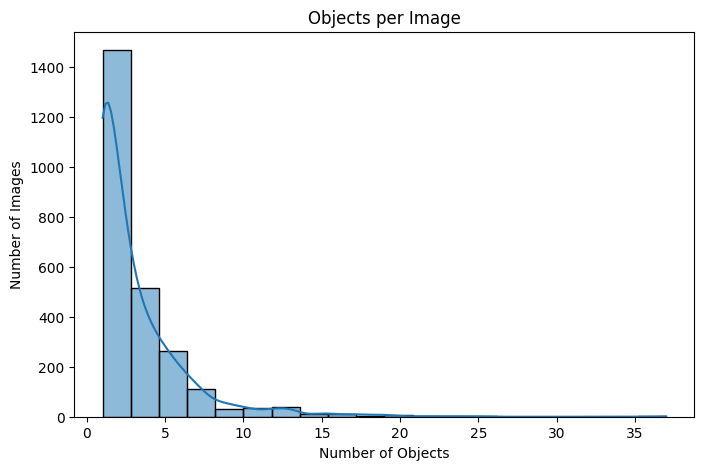

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    objects_per_image,
    bins=20,
    kde=True
)

plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")
plt.title("Objects per Image")

plt.show()

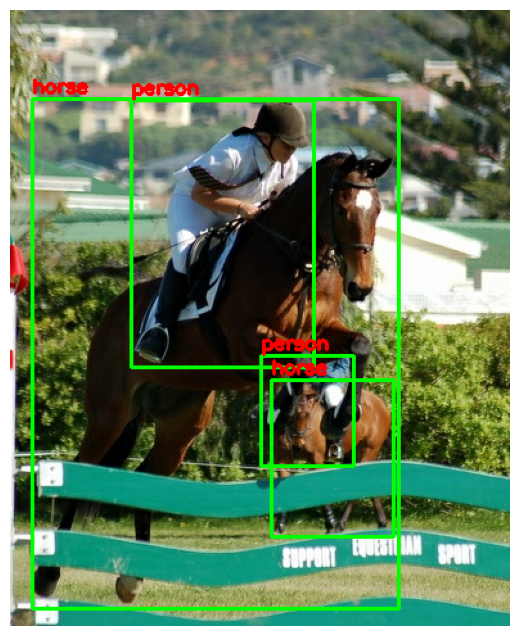

In [11]:
example = next(iter(train_ds))

image = example["image"].numpy()
height, width = image.shape[:2]

boxes = example["objects"]["bbox"].numpy()
labels = example["objects"]["label"].numpy()

for box, label in zip(boxes, labels):

    ymin, xmin, ymax, xmax = box

    x1 = int(xmin * width)
    y1 = int(ymin * height)
    x2 = int(xmax * width)
    y2 = int(ymax * height)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    cv2.putText(
        image,
        class_names[int(label)],
        (x1, max(15, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

In [12]:
#MAKE IT YOLO COMPctiable
base_dir = "/content/VOC_YOLO"

splits = ["train", "val", "test"]

for split in splits:

    os.makedirs(
        f"{base_dir}/images/{split}",
        exist_ok=True
    )

    os.makedirs(
        f"{base_dir}/labels/{split}",
        exist_ok=True
    )

In [13]:
def convert_voc_to_yolo(dataset, split):

    for idx, example in enumerate(dataset):

        image = example["image"].numpy()

        height, width = image.shape[:2]

        filename = f"{idx:06d}"

        # Save image
        image_path = (
            f"{base_dir}/images/{split}/{filename}.jpg"
        )

        Image.fromarray(image).convert("RGB").save(
            image_path
        )

        # Extract annotations
        boxes = example["objects"]["bbox"].numpy()
        labels = example["objects"]["label"].numpy()

        label_path = (
            f"{base_dir}/labels/{split}/{filename}.txt"
        )

        with open(label_path, "w") as f:

            for box, label in zip(boxes, labels):

                ymin, xmin, ymax, xmax = box

                # Convert to YOLO format
                x_center = (xmin + xmax) / 2
                y_center = (ymin + ymax) / 2

                box_width = xmax - xmin
                box_height = ymax - ymin

                # Validate bounding box
                if box_width <= 0 or box_height <= 0:
                    continue

                f.write(
                    f"{int(label)} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{box_width:.6f} "
                    f"{box_height:.6f}\n"
                )

    print(f"{split} conversion completed!")

In [14]:
convert_voc_to_yolo(train_ds, "train")
convert_voc_to_yolo(val_ds, "val")
convert_voc_to_yolo(test_ds, "test")

train conversion completed!
val conversion completed!
test conversion completed!


In [15]:
import yaml

data_config = {
    "path": base_dir,

    "train": "images/train",
    "val": "images/val",
    "test": "images/test",

    "nc": len(class_names),

    "names": class_names
}

with open(f"{base_dir}/data.yaml", "w") as f:
    yaml.dump(data_config, f, sort_keys=False)

print("Dataset YAML created!")

Dataset YAML created!


In [16]:
!pip install -q -U ultralytics

In [17]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.info()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

In [18]:
import torch
from ultralytics import YOLO

# Safely load the model in this cell
model = YOLO("yolov8n.pt")

# Auto-detect device: use 0 (GPU) if CUDA is available, otherwise fall back to cpu
device_target = 0 if torch.cuda.is_available() else "cpu"

# Train using Pascal VOC
results = model.train(
    data="/content/VOC_YOLO/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=device_target,
    workers=2,
    patience=20,
    project="/content/VOC_Experiments",
    name="YOLOv8n_VOC",
    plots=True,
    seed=42
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VOC_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_VOC, nbs=64, nms=None, opset=None, optimize=False, op

In [20]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/VOC_Experiments/YOLOv8n_VOC/weights/best.pt"
)

In [22]:
metrics = best_model.val(
    data="/content/VOC_YOLO/data.yaml",
    split="val",
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 869.8±400.9 MB/s, size: 42.0 KB)
val: Scanning /content/VOC_YOLO/labels/val.cache... 2510 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2510/2510 526.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 5.5it/s 28.5s
                   all       2510       7818      0.694      0.642      0.696      0.477
             aeroplane        127        175      0.882      0.726      0.798        0.6
               bicycle        133        216      0.838      0.634      0.739      0.496
                  bird        151        305      0.704      0.452      0.567      0.361
                  boat        101        190      0.634      0.574      0.589      0.338
                bottle        109        29

In [23]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Precision: 0.6942926262444111
Recall: 0.6422442940481745
mAP50: 0.6958941712205242
mAP50-95: 0.476653832676741


In [24]:
results = best_model.predict(
    source="/content/VOC_YOLO/images/test",
    conf=0.25,
    save=True,
    imgsz=640
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/4952 /content/VOC_YOLO/images/test/000000.jpg: 448x640 1 chair, 1 dog, 1 tvmonitor, 9.2ms
image 2/4952 /content/VOC_YOLO/images/test/000001.jpg: 480x640 1 bicycle, 1 car, 5 persons, 39.6ms
image 3/4952 /content/VOC_YOLO/images/test/000002.jpg: 448x640 2 tvmonitors, 11.0ms
image 4/4952 /content/VOC_YOLO/images/test/000003.jpg: 480x640 1 dog, 1 sheep, 10.7ms
image 5/4952 /content/VOC_YOLO/images/test/000004.jpg: 480x640 4 persons, 10.0ms
image 6/495

In [25]:
# Print results as percentages
print("Precision:", round(metrics.box.mp * 100, 2), "%")
print("Recall:", round(metrics.box.mr * 100, 2), "%")
print("mAP50:", round(metrics.box.map50 * 100, 2), "%")
print("mAP50-95:", round(metrics.box.map * 100, 2), "%")

Precision: 69.43 %
Recall: 64.22 %
mAP50: 69.59 %
mAP50-95: 47.67 %


In [26]:
print("mAP50:", round(metrics.box.map50 * 100, 2), "%")
print("Precision:", round(metrics.box.mp * 100, 2), "%")

mAP50: 69.59 %
Precision: 69.43 %


In [27]:
metrics = best_model.val(
    data="/content/VOC_YOLO/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 700.1±732.3 MB/s, size: 37.5 KB)
val: Scanning /content/VOC_YOLO/labels/test... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 836.8it/s 5.9s
val: New cache created: /content/VOC_YOLO/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 6.8it/s 45.7s
                   all       4952      14976      0.711      0.626      0.684      0.467
             aeroplane        205        311      0.882      0.659      0.772      0.538
               bicycle        250        389      0.847      0.639      0.751      0.512
                  bird        289        576      0.812        0.5      0.663      0.418
                  boat        176        393      0.646      0.453      0.517 

In [28]:
# Print results as percentages
print("Precision:", round(metrics.box.mp * 100, 2), "%")
print("Recall:", round(metrics.box.mr * 100, 2), "%")
print("mAP50:", round(metrics.box.map50 * 100, 2), "%")
print("mAP50-95:", round(metrics.box.map * 100, 2), "%")


Precision: 71.12 %
Recall: 62.63 %
mAP50: 68.45 %
mAP50-95: 46.72 %
